# Credit Risk Analytics — Python Exploratory Data Analysis

This notebook analyzes behavioral and financial risk indicators associated with next-month credit default.

The dataset was previously cleaned and transformed in SQL Server, where engineered features such as delay frequency, delay severity, credit utilization, and payment ratio were created.

The objective of this Python analysis is to validate those features, explore customer risk patterns, and identify meaningful behavioral segments that can support credit-risk monitoring and business decision-making.

In [1]:
import pandas as pd
import numpy as np
import pyodbc
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings(
    "ignore",
    message="pandas only supports SQLAlchemy connectable"
)

## 1. Data Import from SQL Server

The analysis uses the SQL view `vw_CustomerRiskFeatures`, which contains the original customer-level data together with the engineered risk features created during the SQL phase.

In [2]:
connection = pyodbc.connect(
     r"DRIVER={ODBC Driver 18 for SQL Server};"
    r"SERVER=DESKTOP-C7BVI2G\SQLEXPRESS;"
    r"DATABASE=CreditRiskPortfolio;"
    r"Trusted_Connection=yes;"
    r"TrustServerCertificate=yes;"
)
print('Connection successful')

Connection successful


In [3]:
query = """
SELECT * 
FROM dbo.vw_CustomerRiskFeatures """
df = pd.read_sql(query,connection)
df.head()

,ID,DEFAULT_NEXT_MONTH,LIMIT_BAL,BILL_AMT1,PAY_AMT1,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,...,PAY_AMT5,PAY_AMT6,EducationCategory,MarriageCategory,HasPreviousDelay,DelayedMonths,MaxDelay,CreditUtilization,PaymentRatio,RiskGroup
0,25541,1,150000,179441,7333,2,3,1,45,2,...,2000,2200,High School,Married,1,3,2,119.63,4.09,HighUtilization_LowPayment
1,25542,0,70000,9195,1041,2,3,1,44,0,...,2000,2000,High School,Married,0,0,0,13.14,11.32,OtherValidBehavior
2,25543,0,320000,44566,2054,2,1,2,35,0,...,1059,551,Graduate School,Single,0,0,0,13.93,4.61,OtherValidBehavior
3,25544,1,330000,0,0,2,1,1,41,1,...,0,0,Graduate School,Married,1,1,1,0.00,NaN,NotComparable
4,25545,0,120000,106469,5400,2,2,1,37,0,...,5500,1000,University,Married,0,0,0,88.72,5.07,HighUtilization_LowPayment


## 2. Data Validation

Before performing the exploratory analysis, the dataset is validated to confirm row count, data types, missing values, unique customer IDs, and the distribution of the target variable.

In [4]:
df.shape

(30000, 33)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 33 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  30000 non-null  int64  
 1   DEFAULT_NEXT_MONTH  30000 non-null  int64  
 2   LIMIT_BAL           30000 non-null  int64  
 3   BILL_AMT1           30000 non-null  int64  
 4   PAY_AMT1            30000 non-null  int64  
 5   SEX                 30000 non-null  int64  
 6   EDUCATION           30000 non-null  int64  
 7   MARRIAGE            30000 non-null  int64  
 8   AGE                 30000 non-null  int64  
 9   PAY_0               30000 non-null  int64  
 10  PAY_2               30000 non-null  int64  
 11  PAY_3               30000 non-null  int64  
 12  PAY_4               30000 non-null  int64  
 13  PAY_5               30000 non-null  int64  
 14  PAY_6               30000 non-null  int64  
 15  BILL_AMT2           30000 non-null  int64  
 16  BILL_AMT3      

In [6]:
df.isnull().sum()

ID                       0
DEFAULT_NEXT_MONTH       0
LIMIT_BAL                0
BILL_AMT1                0
PAY_AMT1                 0
SEX                      0
EDUCATION                0
MARRIAGE                 0
AGE                      0
PAY_0                    0
PAY_2                    0
PAY_3                    0
PAY_4                    0
PAY_5                    0
PAY_6                    0
BILL_AMT2                0
BILL_AMT3                0
BILL_AMT4                0
BILL_AMT5                0
BILL_AMT6                0
PAY_AMT2                 0
PAY_AMT3                 0
PAY_AMT4                 0
PAY_AMT5                 0
PAY_AMT6                 0
EducationCategory        0
MarriageCategory         0
HasPreviousDelay         0
DelayedMonths            0
MaxDelay                 0
CreditUtilization        0
PaymentRatio          2598
RiskGroup                0
dtype: int64

In [7]:
df['DEFAULT_NEXT_MONTH'].value_counts()

DEFAULT_NEXT_MONTH
0    23364
1     6636
Name: count, dtype: int64

In [8]:
df['ID'].duplicated().sum()

np.int64(0)

In [9]:
df["DEFAULT_NEXT_MONTH"].value_counts(normalize=True) * 100

DEFAULT_NEXT_MONTH
0    77.88
1    22.12
Name: proportion, dtype: float64

## 3. Exploratory Analysis of Risk Features

The engineered risk features are first examined to understand their distributions and identify unusual or extreme values that may influence the analysis.

In [10]:
features = ['DelayedMonths', 'MaxDelay', 'CreditUtilization','PaymentRatio']
df[features].describe().round(2)

,DelayedMonths,MaxDelay,CreditUtilization,PaymentRatio
count,30000.00,30000.00,30000.00,27402.00
mean,0.83,0.68,42.38,177.61
std,1.55,1.07,41.15,7657.45
min,0.00,0.00,-61.99,0.00
25%,0.00,0.00,2.20,3.74
50%,0.00,0.00,31.40,6.11
75%,1.00,2.00,82.98,27.40
max,6.00,8.00,645.53,1145366.67


### 3.1 Extreme Value Review

**Business question:** Are extreme values in payment ratio and credit utilization potential data-quality problems, or do they represent valid customer behavior?

Extreme values are inspected before segmentation instead of being automatically removed.

In [11]:
df['PaymentRatio'].quantile([0.50,0.75,0.90,0.95,0.99,0.995,0.999]).round(2)

0.500        6.11
0.750       27.40
0.900      120.77
0.950      283.12
0.990     1736.16
0.995     3142.42
0.999    10315.39
Name: PaymentRatio, dtype: float64

In [12]:
df[['ID','DEFAULT_NEXT_MONTH','LIMIT_BAL','BILL_AMT1','PAY_AMT1','PaymentRatio']].nlargest(5,'PaymentRatio')

,ID,DEFAULT_NEXT_MONTH,LIMIT_BAL,BILL_AMT1,PAY_AMT1,PaymentRatio
18430,13971,0,50000,3,34361,1145366.67
3988,3413,0,160000,3,13333,444433.33
22136,17677,0,280000,47,99007,210653.19
25458,20999,0,200000,80,90001,112501.25
29574,25115,1,360000,1,1001,100100.00


In [13]:
df[['ID','DEFAULT_NEXT_MONTH','LIMIT_BAL','BILL_AMT1','PAY_AMT1','CreditUtilization']].nlargest(5,'CreditUtilization')

,ID,DEFAULT_NEXT_MONTH,LIMIT_BAL,BILL_AMT1,PAY_AMT1,CreditUtilization
4372,3797,0,20000,129106,4420,645.53
10964,7509,0,10000,53095,2134,530.95
25095,20636,0,20000,82812,2697,414.06
21162,16703,0,30000,118587,6624,395.29
18125,13666,0,20000,74510,2734,372.55


In [14]:
df[['ID','DEFAULT_NEXT_MONTH','LIMIT_BAL','BILL_AMT1','PAY_AMT1','CreditUtilization']].nsmallest(5,'CreditUtilization')

,ID,DEFAULT_NEXT_MONTH,LIMIT_BAL,BILL_AMT1,PAY_AMT1,CreditUtilization
27463,23004,0,250000,-154973,225066,-61.99
15786,12331,0,300000,-165580,505000,-55.19
16721,29780,0,50000,-11545,10000,-23.09
6128,5553,0,10000,-2000,4475,-20.00
5211,4636,0,50000,-9802,10000,-19.60


In [15]:
extreme_summary = { 'PaymentRatio > 100%': (df['PaymentRatio'] >100).sum(),
                   'PaymentRatio > 1000%': (df['PaymentRatio'] > 1000).sum(),
                   'CreditUtilization > 100%': (df['CreditUtilization'] > 100).sum(),
                   'CreditUtilization < 0%':  (df['CreditUtilization'] < 0).sum()} 
extreme_summary 

{'PaymentRatio > 100%': np.int64(3200),
 'PaymentRatio > 1000%': np.int64(461),
 'CreditUtilization > 100%': np.int64(2113),
 'CreditUtilization < 0%': np.int64(450)}

The review confirmed that extreme values in `PaymentRatio` and `CreditUtilization` are mathematically consistent with the underlying balances and payments.

For this reason, these observations are retained and treated as valid customer behavior rather than automatically classified as data errors.

## 4. Payment Delay Behavior

Payment history is analyzed through three complementary dimensions:

- **Frequency:** how many observed months contained a confirmed payment delay.
- **Severity:** the maximum observed delay level.
- **Recency:** whether the most recent payment-status period contained a confirmed delay.

### 4.1 Delay Frequency

**Business question:** Does default risk increase as customers accumulate more delayed months?

In [16]:
delayed_months_summary = (
    df.groupby("DelayedMonths")["DEFAULT_NEXT_MONTH"].agg(
          TotalCustomers="count",
          DefaultCustomers="sum",
          DefaultRate="mean"))

delayed_months_summary["DefaultRate"] = (
    delayed_months_summary["DefaultRate"] * 100
).round(2)

delayed_months_summary

,TotalCustomers,DefaultCustomers,DefaultRate
DelayedMonths,,,
0,19931,2334,11.71
1,4426,1320,29.82
2,1899,736,38.76
3,1154,587,50.87
4,951,545,57.31
5,298,171,57.38
6,1341,943,70.32


Default risk increases substantially as the number of delayed months rises. Customers with no confirmed delayed months had an 11.71% default rate, while customers with delays in all six observed months reached 70.32%.

This suggests that repeated payment delays are a strong behavioral indicator of next-month default risk.

### 4.2 Delay Severity

**Business question:** Is a more severe payment delay associated with a higher probability of default?

In [17]:
max_delay_summary = (
    df.groupby("MaxDelay")["DEFAULT_NEXT_MONTH"].agg(
          TotalCustomers="count",
          DefaultCustomers="sum",
          DefaultRate="mean"))

max_delay_summary["DefaultRate"] = (
    max_delay_summary["DefaultRate"] * 100
).round(2)

max_delay_summary

,TotalCustomers,DefaultCustomers,DefaultRate
MaxDelay,,,
0,19931,2334,11.71
1,1689,422,24.99
2,7187,3130,43.55
3,789,491,62.23
4,218,140,64.22
5,69,35,50.72
6,25,14,56.00
7,67,56,83.58
8,25,14,56.00


Higher delay severity is generally associated with higher default risk. However, the highest delay levels contain relatively few customers, producing more volatile default-rate estimates.

For this reason, severity should be interpreted together with customer volume and other behavioral indicators.

### 4.3 Recent Payment Delay

**Business question:** How strongly is a recent confirmed payment delay associated with next-month default?

In [18]:
df['RecentDelayFlag'] = (df['PAY_0'] >=1).astype(int)

In [19]:
recent_delay_summary = (
    df.groupby("RecentDelayFlag")["DEFAULT_NEXT_MONTH"].agg(
          TotalCustomers="count",
          DefaultCustomers="sum",
          DefaultRate="mean"))

recent_delay_summary["DefaultRate"] = (
    recent_delay_summary["DefaultRate"] * 100).round(2)

recent_delay_summary

,TotalCustomers,DefaultCustomers,DefaultRate
RecentDelayFlag,,,
0,23182,3207,13.83
1,6818,3429,50.29


Customers with a recent confirmed delay had a 50.29% default rate, compared with 13.83% among customers without a recent confirmed delay.

Recent payment behavior therefore provides a strong signal for identifying customers with elevated next-month default risk.

### 4.4 Combined Recency and Frequency Segmentation

**Business question:** Does combining recent payment delay with historical delay frequency identify customer groups with different levels of default risk?

Customers are segmented using both recent delay status and the number of delayed months to capture complementary dimensions of payment behavior.

In [20]:
df['DelayFrequencyGroup'] = np.where(
    df['DelayedMonths'] <= 1, 'low', 'high')

In [21]:
df["FrequencyDelay"] = np.select(
    [
        (df["RecentDelayFlag"] == 1) & (df["DelayFrequencyGroup"] == "high"),
        (df["RecentDelayFlag"] == 1) & (df["DelayFrequencyGroup"] == "low"),
        (df["RecentDelayFlag"] == 0) & (df["DelayFrequencyGroup"] == "high"),
        (df["RecentDelayFlag"] == 0) & (df["DelayFrequencyGroup"] == "low")],
    [
        "Recent_High",
        "Recent_Low",
        "NoRecent_High",
        "NoRecent_Low"
    ],
    default="Unknown"
)

In [22]:
frequency_delay_summary = ( 
    df.groupby('FrequencyDelay')['DEFAULT_NEXT_MONTH'].agg(
        TotalCustomers = 'count',
        DefaultCustomers = 'sum',
        DefaultRate = 'mean'))

frequency_delay_summary['DefaultRate'] = (
    frequency_delay_summary['DefaultRate'] * 100).round(2)

frequency_delay_summary

,TotalCustomers,DefaultCustomers,DefaultRate
FrequencyDelay,,,
NoRecent_High,1194,407,34.09
NoRecent_Low,21988,2800,12.73
Recent_High,4449,2575,57.88
Recent_Low,2369,854,36.05


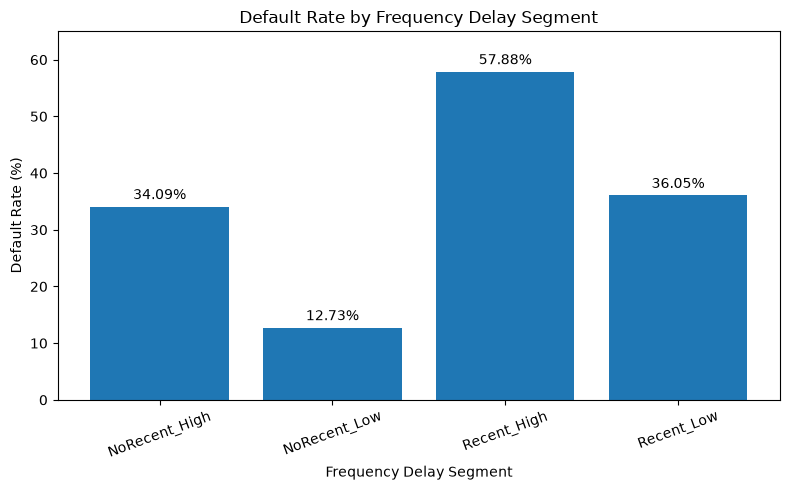

In [23]:
plt.figure(figsize=(8,5))
           
bars = plt.bar(frequency_delay_summary.index,
        frequency_delay_summary['DefaultRate'])

plt.bar_label(bars, fmt ='%.2f%%', padding =3)

plt.title('Default Rate by Frequency Delay Segment')
plt.xlabel('Frequency Delay Segment')
plt.ylabel('Default Rate (%)')

plt.ylim(0,65)
plt.xticks(rotation=20)
plt.tight_layout()

plt.show()

The combined segmentation shows a clear separation in default risk.

Customers in the `Recent_High` segment had the highest default rate at 57.88%, while the `NoRecent_Low` segment had the lowest at 12.73%.

This indicates that recent payment delay and repeated historical delays provide complementary information and are more informative when analyzed together.

## 5. Credit Utilization Risk

**Business question:** Does default risk increase as customers use a larger proportion of their available credit?

Credit utilization is grouped into interpretable bands to compare default rates across different levels of balance usage.

In [24]:
df["CreditUtilizationBand"] = np.select(
    [df["CreditUtilization"] < 0,
        (df["CreditUtilization"] >= 0) & (df["CreditUtilization"] < 30),
        (df["CreditUtilization"] >= 30) & (df["CreditUtilization"] < 60),
        (df["CreditUtilization"] >= 60) & (df["CreditUtilization"] < 80),
        (df["CreditUtilization"] >= 80) & (df["CreditUtilization"] < 100),
        df["CreditUtilization"] >= 100],
    ["Negative Balance",
        "0-29%",
        "30-59%",
        "60-79%",
        "80-99%",
        "100%+"],
    default="Unknown")

In [25]:
credit_utilization_summary = (
    df.groupby('CreditUtilizationBand')['DEFAULT_NEXT_MONTH'].agg(
        TotalCustomers = 'count',
        DefaultCustomers = 'sum',
        DefaultRate = 'mean'))

credit_utilization_summary['DefaultRate'] = (
    credit_utilization_summary['DefaultRate'] * 100).round(2)



In [26]:
band_order = [
    "Negative Balance",
    "0-29%",
    "30-59%",
    "60-79%",
    "80-99%",
    "100%+"
]
credit_utilization_summary = credit_utilization_summary.reindex(band_order)

credit_utilization_summary

,TotalCustomers,DefaultCustomers,DefaultRate
CreditUtilizationBand,,,
Negative Balance,450,79,17.56
0-29%,14341,2629,18.33
30-59%,4306,998,23.18
60-79%,2923,797,27.27
80-99%,5853,1495,25.54
100%+,2127,638,30.00


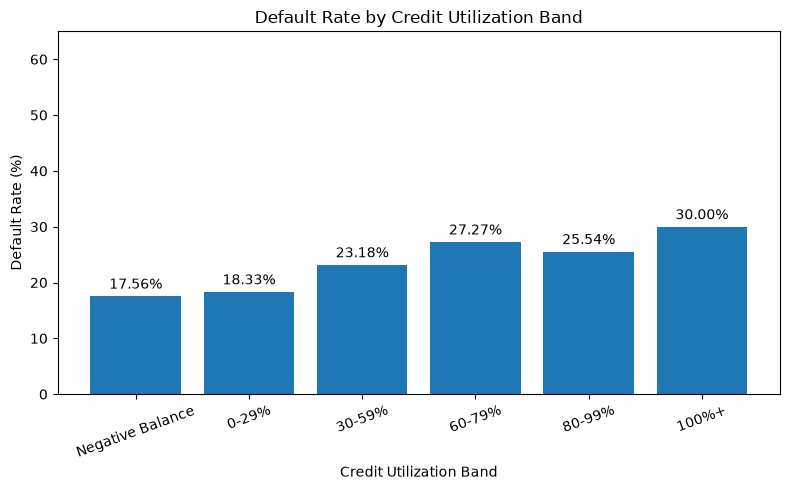

In [27]:
plt.figure(figsize=(8,5))

bars = plt.bar(
    credit_utilization_summary.index,
    credit_utilization_summary["DefaultRate"])
plt.bar_label(bars, fmt ='%.2f%%', padding =3)
plt.title('Default Rate by Credit Utilization Band')
plt.xlabel('Credit Utilization Band')
plt.ylabel('Default Rate (%)')

plt.ylim(0,65)
plt.xticks(rotation=20)
plt.tight_layout()

plt.show()


Customers in the 100%+ utilization group had the highest default rate at 30.00%. In contrast, customers in the 0–29% utilization group had a default rate of 18.33%. Overall, default risk generally increased as credit utilization rose, although the relationship was not perfectly linear.

## 6. Payment Ratio Risk

**Business question:** Does the proportion of the billed balance that a customer pays relate to their probability of default?

Payment ratio is grouped into interpretable bands to compare default risk across different repayment behaviors. Customers with negative or zero billed balances are kept as separate groups because their payment ratios are not directly comparable with standard repayment behavior.

In [28]:
df['PaymentRatioBand'] = np.select(
    [df["BILL_AMT1"] < 0,
    df["BILL_AMT1"] == 0,
     df['PaymentRatio'] == 0,
    (df["PaymentRatio"] > 0) & (df["PaymentRatio"] < 25),
    (df["PaymentRatio"] >= 25) & (df["PaymentRatio"] < 50),
    (df["PaymentRatio"] >= 50) & (df["PaymentRatio"] < 100),
    df["PaymentRatio"] >= 100],
['Negative Balance',
    'No Bill / Zero Balance',
    '0%',
    '1-24%',
    '25-49%',
    '50-99%',
    '100%+'],
     default="Unknown")
    

In [29]:
payment_ratio_summary = (
    df.groupby("PaymentRatioBand")["DEFAULT_NEXT_MONTH"].agg(
        TotalCustomers="count",
        DefaultCustomers="sum",
        DefaultRate="mean"))

payment_ratio_summary["DefaultRate"] = (
    payment_ratio_summary["DefaultRate"] * 100).round(2)

payment_band_order = [
    "Negative Balance",
    "No Bill / Zero Balance",
    "0%",
    "1-24%",
    "25-49%",
    "50-99%",
    "100%+"]

payment_ratio_summary = payment_ratio_summary.reindex(payment_band_order)

payment_ratio_summary

,TotalCustomers,DefaultCustomers,DefaultRate
PaymentRatioBand,,,
Negative Balance,590,109,18.47
No Bill / Zero Balance,2008,534,26.59
0%,3519,1401,39.81
1-24%,16799,3497,20.82
25-49%,1644,282,17.15
50-99%,1569,213,13.58
100%+,3871,600,15.50


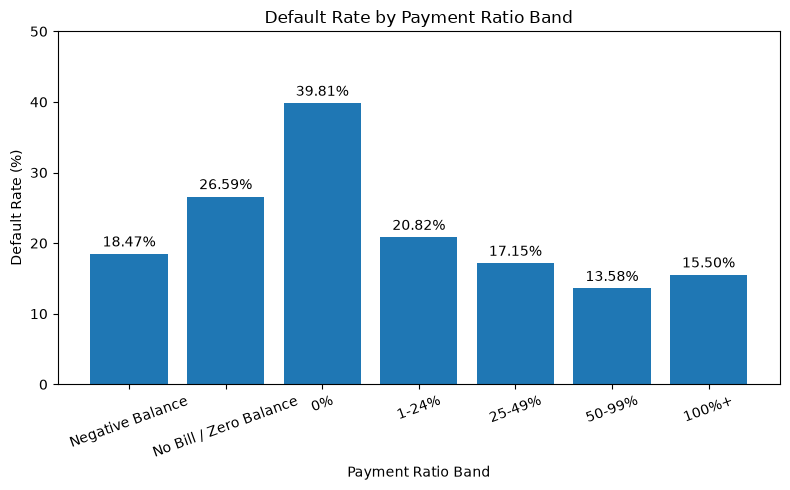

In [30]:
plt.figure(figsize=(8,5))

bars = plt.bar(
    payment_ratio_summary.index,
    payment_ratio_summary["DefaultRate"])
plt.bar_label(bars, fmt ='%.2f%%', padding =3)
plt.title('Default Rate by Payment Ratio Band')
plt.xlabel('Payment Ratio Band')
plt.ylabel('Default Rate (%)')

plt.ylim(0,50)
plt.xticks(rotation=20)
plt.tight_layout()

plt.show()

Customers who paid 0% of their billed balance had the highest default rate at 39.81%. In contrast, customers who paid between 50% and 99% had the lowest default rate at 13.58%. Overall, a higher payment ratio is generally associated with a lower probability of default, although the relationship is not perfectly linear.

## 7. Key Business Insights

The analysis identified several behavioral and financial indicators strongly associated with next-month default risk:

1. **Repeated payment delays are one of the strongest risk indicators.**  
   Customers with no confirmed delayed months had an 11.71% default rate, while customers with delays in all six observed months reached 70.32%.

2. **Recent payment behavior is highly informative.**  
   Customers with a recent confirmed delay had a 50.29% default rate, compared with 13.83% among customers without a recent delay.

3. **Combining recency and frequency improves customer segmentation.**  
   The `Recent_High` segment had the highest default rate at 57.88%, while the `NoRecent_Low` segment had the lowest at 12.73%. This suggests that recent and repeated delays provide complementary information when identifying higher-risk customers.

4. **Higher credit utilization is generally associated with higher default risk.**  
   Customers with credit utilization above 100% had a 30.00% default rate, compared with 18.33% among customers using 0–29% of their available credit.

5. **Stronger repayment behavior is generally associated with lower default risk.**  
   Customers who paid 0% of their billed balance had a 39.81% default rate, while customers who paid between 50% and 99% had a default rate of 13.58%.

### Business Interpretation

The results suggest that payment history should be a central component of credit-risk monitoring. Customers showing recent delays, repeated delays, high credit utilization, and low repayment ratios may require closer monitoring or earlier intervention.

These indicators should not be interpreted as deterministic predictors of default, but as behavioral signals that can help prioritize customers for further risk assessment.